# Judged Output Analysis
Analyzes RAG evaluation results across difficulty, language, context mode, and prompt variant.

In [26]:
import glob
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 120

## 1. Load judged files

In [27]:
# Adjust glob pattern to load one or many judged CSVs
OUTPUTS_DIR = Path("../data")
JUDGED_PATTERN = "**/*__judged.csv"  # recursive search

files = sorted(OUTPUTS_DIR.glob(JUDGED_PATTERN))
print(f"Found {len(files)} judged file(s):")
for f in files:
    print(" ", f.relative_to(OUTPUTS_DIR))

Found 1 judged file(s):
  generation step/multilingual_claude_sonnet4_answers__judged.csv


In [28]:
dfs = []
for f in files:
    tmp = pd.read_csv(f)
    # ensure source file is traceable
    if "source_file" not in tmp.columns:
        tmp["source_file"] = f.name
    dfs.append(tmp)

df = pd.concat(dfs, ignore_index=True)
print(f"Total rows loaded: {len(df)}")
df.head(3)

Total rows loaded: 300


,language,query_id,query,distractor_id,distractor_text,distractor_title,gold_judge_text,gold_generation_text,gold_generation_id,n_positives,...,tfidf_sim,semantic_sim,compound_sim,difficulty,answer_with_distractor_claude,judge_label,judge_reasoning,judge_raw_json,judge_error,source_file
0,en,1062,When was the song American Pie first recorded?,7049580#3,The following story about an argument between ...,We're an American Band (song),"""American Pie"" is a song by American singer an...",American Pie is the second studio album by the...,750254#0,3,...,0.127273,0.494936,0.874741,easy,The context passage does not contain informati...,ABSTAIN,Model states context lacks information to answer.,"{""label"": ""ABSTAIN"", ""reasoning"": ""Model state...",NaN,multilingual_claude_sonnet4_answers__judged.csv
1,en,1062,When was the song American Pie first recorded?,51744#4,Except to acknowledge that he first learned ab...,American Pie (song),"""American Pie"" is a song by American singer an...",American Pie is the second studio album by the...,750254#0,3,...,0.227076,0.601566,1.027859,hard,The context passage does not provide informati...,ABSTAIN,Model states context lacks the requested infor...,"{""label"": ""ABSTAIN"", ""reasoning"": ""Model state...",NaN,multilingual_claude_sonnet4_answers__judged.csv
2,en,1062,When was the song American Pie first recorded?,1403903#0,Flaming Pie is the tenth solo studio album by ...,Flaming Pie,"""American Pie"" is a song by American singer an...",American Pie is the second studio album by the...,750254#0,3,...,0.205606,0.495710,0.953461,medium,The context passage does not contain informati...,ABSTAIN,Model states context lacks information to answer.,"{""label"": ""ABSTAIN"", ""reasoning"": ""Model state...",NaN,multilingual_claude_sonnet4_answers__judged.csv


## 2. Clean & validate

In [29]:
LABELS = ["CORRECT", "ABSTAIN", "INCORRECT"]
DIFFICULTIES = ["easy", "medium", "hard"]
LABEL_COLORS = {"CORRECT": "#4caf50", "ABSTAIN": "#ff9800", "INCORRECT": "#f44336"}

df["judge_label"] = df["judge_label"].astype(str).str.strip().str.upper()
df["difficulty"]  = df["difficulty"].astype(str).str.strip().str.lower()

# keep only valid rows for label analysis
valid = df[df["judge_label"].isin(LABELS)].copy()
print(f"Valid judged rows: {len(valid)} / {len(df)}")
print(f"Missing / invalid labels: {len(df) - len(valid)}")
valid["judge_label"].value_counts()

Valid judged rows: 300 / 300
Missing / invalid labels: 0


judge_label
ABSTAIN      222
INCORRECT     56
CORRECT       22
Name: count, dtype: int64

## 3. Overall label distribution

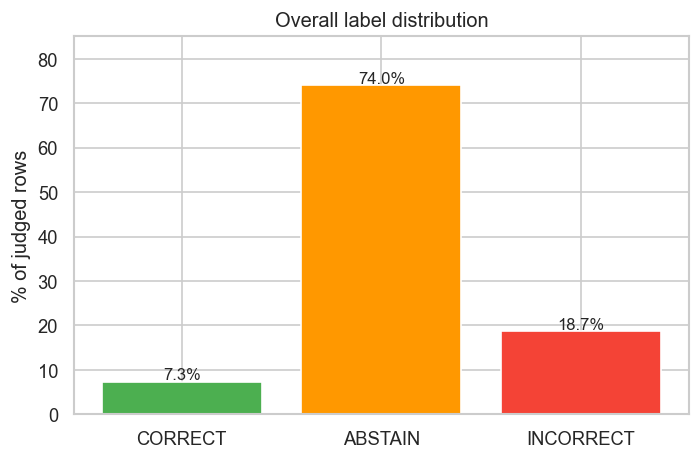

judge_label
CORRECT       22
ABSTAIN      222
INCORRECT     56


In [30]:
counts = valid["judge_label"].value_counts().reindex(LABELS, fill_value=0)
pct    = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(LABELS, pct.values, color=[LABEL_COLORS[l] for l in LABELS], edgecolor="white")
for bar, v in zip(bars, pct.values):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 0.5, f"{v:.1f}%", ha="center", fontsize=10)
ax.set_ylabel("% of judged rows")
ax.set_title("Overall label distribution")
ax.set_ylim(0, pct.max() * 1.15)
plt.tight_layout()
plt.show()
print(counts.to_string())

## 4. Label distribution by difficulty

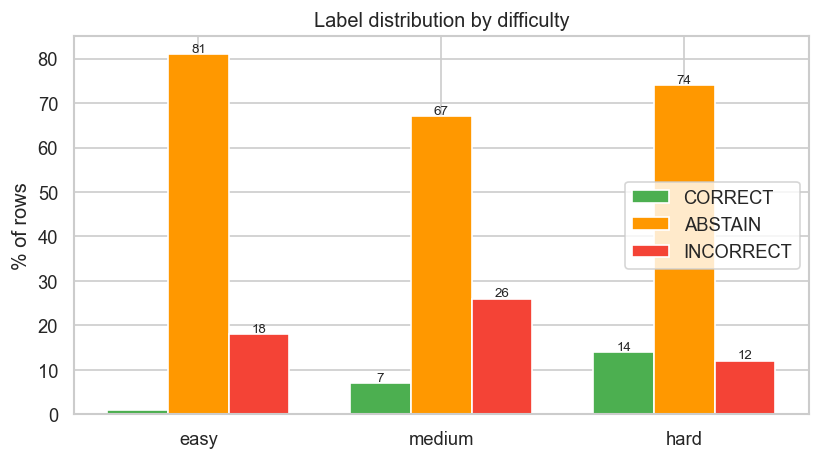

judge_label  CORRECT  ABSTAIN  INCORRECT
difficulty                              
easy             1.0     81.0       18.0
medium           7.0     67.0       26.0
hard            14.0     74.0       12.0


In [31]:
def pct_table(df, group_col, difficulties=DIFFICULTIES):
    """Return a % pivot (rows=group_col, cols=LABELS)."""
    ct = (
        df.groupby([group_col, "judge_label"])
        .size()
        .unstack(fill_value=0)
        .reindex(columns=LABELS, fill_value=0)
    )
    return ct.div(ct.sum(axis=1), axis=0).mul(100).round(1)


diff_valid = valid[valid["difficulty"].isin(DIFFICULTIES)].copy()
diff_pct   = pct_table(diff_valid, "difficulty").reindex(DIFFICULTIES)

fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(DIFFICULTIES))
w = 0.25
for i, label in enumerate(LABELS):
    vals = diff_pct[label].values
    bars = ax.bar(x + i * w, vals, w, label=label, color=LABEL_COLORS[label], edgecolor="white")
    for bar, v in zip(bars, vals):
        if v > 2:
            ax.text(bar.get_x() + bar.get_width() / 2, v + 0.5, f"{v:.0f}", ha="center", fontsize=8)
ax.set_xticks(x + w)
ax.set_xticklabels(DIFFICULTIES)
ax.set_ylabel("% of rows")
ax.set_title("Label distribution by difficulty")
ax.legend()
plt.tight_layout()
plt.show()
print(diff_pct)

## 5. Stacked bar: difficulty × label

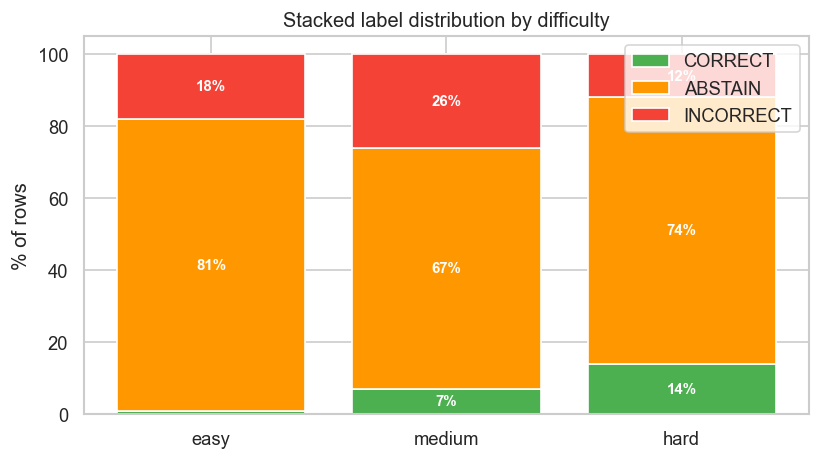

In [32]:
fig, ax = plt.subplots(figsize=(7, 4))
bottom = np.zeros(len(DIFFICULTIES))
for label in LABELS:
    vals = diff_pct.reindex(DIFFICULTIES)[label].values
    ax.bar(DIFFICULTIES, vals, bottom=bottom, label=label, color=LABEL_COLORS[label], edgecolor="white")
    for i, (v, b) in enumerate(zip(vals, bottom)):
        if v > 3:
            ax.text(i, b + v / 2, f"{v:.0f}%", ha="center", va="center", fontsize=9, color="white", fontweight="bold")
    bottom += vals
ax.set_ylabel("% of rows")
ax.set_title("Stacked label distribution by difficulty")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

## 6. Distribution by language (if multilingual)

In [33]:
if "language" in valid.columns and valid["language"].nunique() > 1:
    lang_pct = pct_table(valid, "language").sort_values("CORRECT", ascending=False)

    fig, ax = plt.subplots(figsize=(12, 5))
    langs = lang_pct.index.tolist()
    bottom = np.zeros(len(langs))
    for label in LABELS:
        vals = lang_pct[label].values
        ax.bar(langs, vals, bottom=bottom, label=label, color=LABEL_COLORS[label], edgecolor="white")
        for i, (v, b) in enumerate(zip(vals, bottom)):
            if v > 4:
                ax.text(i, b + v / 2, f"{v:.0f}", ha="center", va="center", fontsize=8, color="white", fontweight="bold")
        bottom += vals
    ax.set_ylabel("% of rows")
    ax.set_title("Stacked label distribution by language")
    ax.legend()
    plt.tight_layout()
    plt.show()
    print(lang_pct)
else:
    print("Single language or no language column — skipping.")

Single language or no language column — skipping.


## 7. CORRECT rate heatmap: language × difficulty

In [34]:
if "language" in valid.columns and valid["language"].nunique() > 1:
    heat = (
        valid[valid["difficulty"].isin(DIFFICULTIES)]
        .groupby(["language", "difficulty", "judge_label"])
        .size()
        .unstack(fill_value=0)
        .reindex(columns=LABELS, fill_value=0)
    )
    heat = heat.div(heat.sum(axis=1), axis=0).mul(100)["CORRECT"].unstack("difficulty").reindex(columns=DIFFICULTIES)

    fig, ax = plt.subplots(figsize=(6, max(4, len(heat) * 0.4 + 1)))
    sns.heatmap(heat, annot=True, fmt=".0f", cmap="RdYlGn", vmin=0, vmax=100, ax=ax,
                linewidths=0.5, cbar_kws={"label": "CORRECT %"})
    ax.set_title("CORRECT rate (%) — language × difficulty")
    ax.set_xlabel("Difficulty")
    ax.set_ylabel("Language")
    plt.tight_layout()
    plt.show()
else:
    print("Single language — skipping heatmap.")

Single language — skipping heatmap.


## 8. Distribution by context mode

In [35]:
if "context_mode" in valid.columns and valid["context_mode"].nunique() > 1:
    mode_pct = pct_table(valid, "context_mode")
    mode_pct.plot(kind="bar", color=[LABEL_COLORS[l] for l in LABELS], edgecolor="white", figsize=(7, 4))
    plt.title("Label distribution by context mode")
    plt.ylabel("% of rows")
    plt.xticks(rotation=0)
    plt.legend()
    plt.tight_layout()
    plt.show()
    print(mode_pct)
else:
    print("Single context_mode — skipping:", valid['context_mode'].unique() if 'context_mode' in valid.columns else 'N/A')

Single context_mode — skipping: N/A


## 9. Distribution by prompt variant

In [36]:
if "prompt_variant" in valid.columns and valid["prompt_variant"].nunique() > 1:
    pv_pct = pct_table(valid, "prompt_variant")
    pv_pct.plot(kind="bar", color=[LABEL_COLORS[l] for l in LABELS], edgecolor="white", figsize=(7, 4))
    plt.title("Label distribution by prompt variant")
    plt.ylabel("% of rows")
    plt.xticks(rotation=0)
    plt.legend()
    plt.tight_layout()
    plt.show()
    print(pv_pct)
else:
    print("Single prompt_variant — skipping:", valid['prompt_variant'].unique() if 'prompt_variant' in valid.columns else 'N/A')

Single prompt_variant — skipping: N/A


## 10. Multi-model comparison (if multiple models in data)

In [37]:
model_col = next((c for c in ["generation_model", "model", "experiment"] if c in valid.columns), None)

if model_col and valid[model_col].nunique() > 1:
    model_pct = pct_table(valid, model_col).sort_values("CORRECT", ascending=True)

    fig, ax = plt.subplots(figsize=(9, max(4, len(model_pct) * 0.5 + 1)))
    bottom = np.zeros(len(model_pct))
    for label in LABELS:
        vals = model_pct[label].values
        ax.barh(model_pct.index, vals, left=bottom, label=label, color=LABEL_COLORS[label], edgecolor="white")
        for i, (v, b) in enumerate(zip(vals, bottom)):
            if v > 4:
                ax.text(b + v / 2, i, f"{v:.0f}", ha="center", va="center", fontsize=8, color="white", fontweight="bold")
        bottom += vals
    ax.set_xlabel("% of rows")
    ax.set_title("Label distribution by model")
    ax.legend()
    plt.tight_layout()
    plt.show()
    print(model_pct)
else:
    print("Single model in data — skipping.")

Single model in data — skipping.


## 11. CORRECT rate: model × difficulty (heatmap)

In [38]:
if model_col and valid[model_col].nunique() > 1:
    heat2 = (
        valid[valid["difficulty"].isin(DIFFICULTIES)]
        .groupby([model_col, "difficulty", "judge_label"])
        .size()
        .unstack(fill_value=0)
        .reindex(columns=LABELS, fill_value=0)
    )
    heat2 = heat2.div(heat2.sum(axis=1), axis=0).mul(100)["CORRECT"].unstack("difficulty").reindex(columns=DIFFICULTIES)

    fig, ax = plt.subplots(figsize=(6, max(4, len(heat2) * 0.5 + 1)))
    sns.heatmap(heat2, annot=True, fmt=".0f", cmap="RdYlGn", vmin=0, vmax=100, ax=ax,
                linewidths=0.5, cbar_kws={"label": "CORRECT %"})
    ax.set_title("CORRECT rate (%) — model × difficulty")
    ax.set_xlabel("Difficulty")
    ax.set_ylabel("Model")
    plt.tight_layout()
    plt.show()
else:
    print("Single model — skipping.")

Single model — skipping.


## 12. Summary table

In [39]:
group_cols = [c for c in [model_col, "context_mode", "prompt_variant", "difficulty"] if c and c in valid.columns]

summary = (
    valid.groupby(group_cols)["judge_label"]
    .value_counts(normalize=True)
    .mul(100)
    .round(1)
    .unstack(fill_value=0)
    .reindex(columns=LABELS, fill_value=0)
)
summary["n"] = valid.groupby(group_cols)["judge_label"].count()
summary

judge_label,CORRECT,ABSTAIN,INCORRECT,n
difficulty,,,,
easy,1.0,81.0,18.0,100
hard,14.0,74.0,12.0,100
medium,7.0,67.0,26.0,100
